<a href="https://colab.research.google.com/github/yashuu-2026/LLM_embeddibngs_learningphase/blob/main/Lung_Cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

In [ ]:
import os
import kagglehub
path = kagglehub.dataset_download("adityamahimkar/iqothnccd-lung-cancer-dataset")
print(path)

Using Colab cache for faster access to the 'iqothnccd-lung-cancer-dataset' dataset.
/kaggle/input/iqothnccd-lung-cancer-dataset


In [ ]:
for root, folders, files in os.walk(path):
    print(root)

/kaggle/input/iqothnccd-lung-cancer-dataset
/kaggle/input/iqothnccd-lung-cancer-dataset/Test cases
/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset
/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset
/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases
/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Bengin cases
/kaggle/input/iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [ ]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

In [ ]:
train_generator = datagen.flow_from_directory(
    path + "/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training')

Found 878 images belonging to 3 classes.


In [ ]:
validation_generator = datagen.flow_from_directory(
    path + "/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation')

Found 219 images belonging to 3 classes.


In [ ]:
print(train_generator.class_indices)

{'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


In [ ]:
model = keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(3, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.fit(train_generator, epochs=5, validation_data=validation_generator,batch_size=BATCH_SIZE)

Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 100s 3s/step - accuracy: 0.5592 - loss: 1.0148 - val_accuracy: 0.6073 - val_loss: 1.0370
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 96s 3s/step - accuracy: 0.8337 - loss: 0.4410 - val_accuracy: 0.5068 - val_loss: 1.6369
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - accuracy: 0.9476 - loss: 0.1679 - val_accuracy: 0.4840 - val_loss: 1.7640
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 96s 3s/step - accuracy: 0.9727 - loss: 0.0911 - val_accuracy: 0.5114 - val_loss: 1.4652
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 96s 3s/step - accuracy: 0.9886 - loss: 0.0373 - val_accuracy: 0.5571 - val_loss: 1.5915


In [ ]:
model.save("LungCancer_multi.h5")

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np
model = load_model('LungCancer_multi.h5')
print("Model Loaded")

Model Loaded


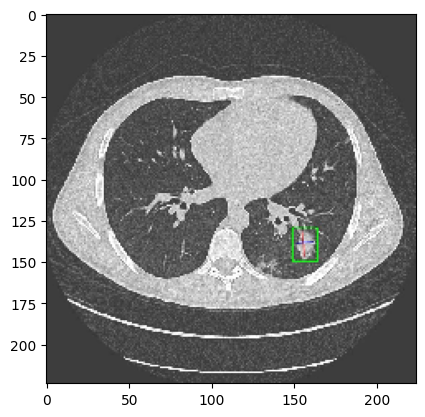

In [ ]:
test_image_path = "/content/lungcancer.jpeg"
img = image.load_img(test_image_path, target_size=(224,224))
plt.imshow(img)
plt.axis()
plt.show()

In [ ]:
img_array=image.img_to_array(img)
img_array=np.expand_dims(img_array,axis=0)
img_array /= 255.

In [ ]:
prediction = model.predict(img_array)
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
[[0.00786541 0.7797101  0.21242443]]


In [ ]:
class_name = list(train_generator.class_indices.keys())
print(class_name)

['Bengin cases', 'Malignant cases', 'Normal cases']
